In [1]:
# Thumbs Gesture Recognition using Machine Learning
# Classes: Thumbs Up, Thumbs Down, Neutral

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

# Create folders for our three gesture classes
dataset_path = "/content/gesture_dataset"

classes = ["thumbs_up", "thumbs_down", "neutral"]

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)
    os.makedirs(folder_path, exist_ok=True)

print("Dataset folders created successfully!")

for class_name in classes:
    print(class_name, ":", os.path.join(dataset_path, class_name))

Dataset folders created successfully!
thumbs_up : /content/gesture_dataset/thumbs_up
thumbs_down : /content/gesture_dataset/thumbs_down
neutral : /content/gesture_dataset/neutral


In [4]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
import os

def capture_image():
    js = Javascript("""
    async function takePhoto() {
        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        button.textContent = 'Capture Photo';
        div.appendChild(video);
        div.appendChild(button);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(
            video, 0, 0, canvas.width, canvas.height
        );

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg', 0.9);
    }
    """)

    display(js)
    image_data = eval_js('takePhoto()')
    image_bytes = b64decode(image_data.split(',')[1])

    return Image.open(io.BytesIO(image_bytes)).convert("RGB")

print("Webcam capture function is ready!")

Webcam capture function is ready!


<IPython.core.display.Javascript object>

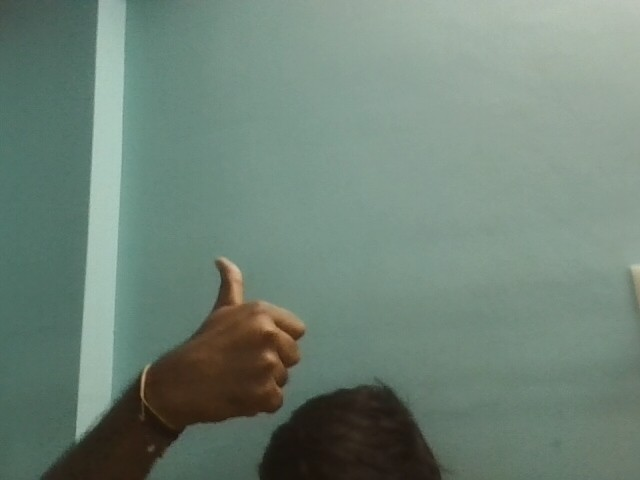

Image captured successfully!


In [6]:
img = capture_image()

display(img)

print("Image captured successfully!")

In [8]:
def collect_images(class_name, number_of_images):
    folder_path = os.path.join(dataset_path, class_name)
    os.makedirs(folder_path, exist_ok=True)

    print(f"Collecting images for: {class_name}")

    for i in range(number_of_images):
        input(f"Prepare gesture {i + 1}/{number_of_images}, then press Enter.")

        captured_img = capture_image()

        file_path = os.path.join(
            folder_path, f"{class_name}_{i + 1}.jpg"
        )

        captured_img.save(file_path)

        print(f"Saved: {file_path}")

    print(f"\nCompleted collecting {number_of_images} images for {class_name}!")

In [11]:
collect_images("thumbs_up", 10)

Prepare gesture 1/10, then press Enter.1


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_up/thumbs_up_1.jpg
Prepare gesture 2/10, then press Enter.2


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_up/thumbs_up_2.jpg
Prepare gesture 3/10, then press Enter.3


...

Saved: /content/gesture_dataset/thumbs_up/thumbs_up_8.jpg
Prepare gesture 9/10, then press Enter.9


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_up/thumbs_up_9.jpg
Prepare gesture 10/10, then press Enter.10


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_up/thumbs_up_10.jpg

Completed collecting 10 images for thumbs_up!


In [12]:
collect_images("thumbs_down", 10)

Prepare gesture 1/10, then press Enter.1


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_down/thumbs_down_1.jpg
Prepare gesture 2/10, then press Enter.2


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_down/thumbs_down_2.jpg
Prepare gesture 3/10, then press Enter.3


...

Saved: /content/gesture_dataset/thumbs_down/thumbs_down_8.jpg
Prepare gesture 9/10, then press Enter.9


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_down/thumbs_down_9.jpg
Prepare gesture 10/10, then press Enter.10


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/thumbs_down/thumbs_down_10.jpg

Completed collecting 10 images for thumbs_down!


In [13]:
collect_images("neutral", 10)

Prepare gesture 1/10, then press Enter.1


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/neutral/neutral_1.jpg
Prepare gesture 2/10, then press Enter.0


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/neutral/neutral_2.jpg
Prepare gesture 3/10, then press Enter.3


...

Saved: /content/gesture_dataset/neutral/neutral_8.jpg
Prepare gesture 9/10, then press Enter.9


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/neutral/neutral_9.jpg
Prepare gesture 10/10, then press Enter.10


<IPython.core.display.Javascript object>

Saved: /content/gesture_dataset/neutral/neutral_10.jpg

Completed collecting 10 images for neutral!


In [14]:
for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)
    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(f"{class_name}: {len(images)} images")

thumbs_up: 10 images
thumbs_down: 10 images
neutral: 10 images


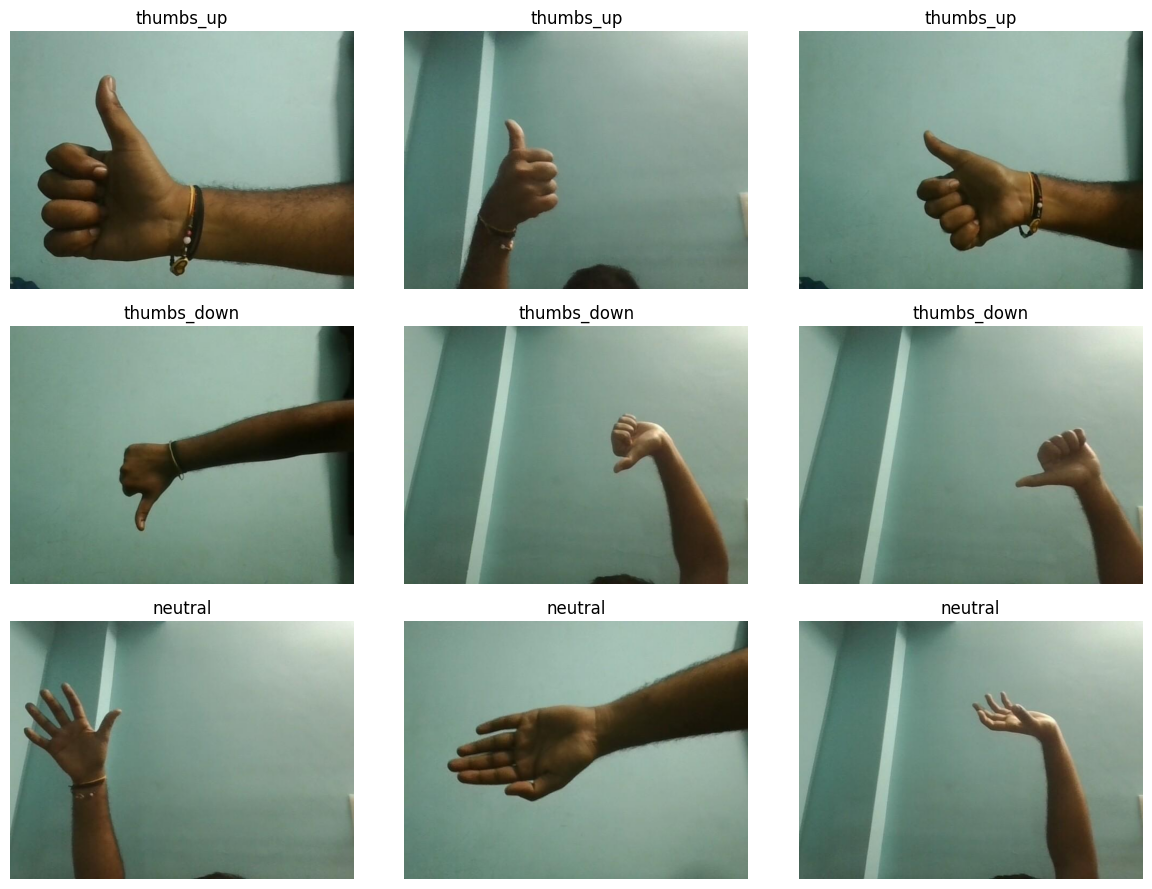

In [15]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# Display a few random images from each class
plt.figure(figsize=(12, 9))

for class_index, class_name in enumerate(classes):
    folder_path = os.path.join(dataset_path, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_images = random.sample(
        image_files, min(3, len(image_files))
    )

    for image_index, image_name in enumerate(selected_images):
        image_path = os.path.join(folder_path, image_name)
        image = Image.open(image_path)

        plt.subplot(3, 3, class_index * 3 + image_index + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
import shutil

dataset_zip = shutil.make_archive(
    "/content/gesture_dataset_backup",
    "zip",
    "/content",
    "gesture_dataset"
)

print("Dataset backup created:", dataset_zip)

Dataset backup created: /content/gesture_dataset_backup.zip


In [17]:
from google.colab import files

files.download("/content/gesture_dataset_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
!git clone https://github.com/imsparsh/Gesture-Recognition-Dataset.git

Cloning into 'Gesture-Recognition-Dataset'...
remote: Enumerating objects: 23539, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 23539 (delta 3), reused 2 (delta 0), pack-reused 23530 (from 1)
Receiving objects: 100% (23539/23539), 1.58 GiB | 25.39 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (22895/22895), done.


In [19]:
import os

repo_path = "/content/Gesture-Recognition-Dataset"

print("Repository downloaded:", os.path.exists(repo_path))
print("\nRepository files:")

for item in os.listdir(repo_path):
    print(item)

Repository downloaded: True

Repository files:
val.csv
val
train.csv
train
LICENSE
README.md
.gitattributes
.git


In [20]:
import pandas as pd

train_csv = os.path.join(repo_path, "train.csv")
val_csv = os.path.join(repo_path, "val.csv")

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

print("Training data:")
display(train_df.head())

print("\nValidation data:")
display(val_df.head())

Training data:


,WIN_20180925_17_08_43_Pro_Left_Swipe_new;Left_Swipe_new;0
0,WIN_20180925_17_18_28_Pro_Left_Swipe_new;Left_...
1,WIN_20180925_17_18_56_Pro_Left_Swipe_new;Left_...
2,WIN_20180925_17_19_51_Pro_Left_Swipe_new;Left_...
3,WIN_20180925_17_20_14_Pro_Left_Swipe_new;Left_...
4,WIN_20180925_17_21_28_Pro_Left_Swipe_new;Left_...



Validation data:


,WIN_20180925_17_17_04_Pro_Left_Swipe_new;Left_Swipe_new;0
0,WIN_20180925_17_43_01_Pro_Left_Swipe_new;Left_...
1,WIN_20180925_18_01_40_Pro_Left_Swipe_new;Left_...
2,WIN_20180925_18_03_21_Pro_Left_Swipe_new;Left_...
3,WIN_20180926_16_46_22_Pro_Left_Swipe_new;Left_...
4,WIN_20180926_16_47_09_Pro_Left_Swipe_new;Left_...


In [21]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTraining data shape:")
print(train_df.shape)

print("\nFirst training row:")
print(train_df.iloc[0].to_dict())

Training columns:
['WIN_20180925_17_08_43_Pro_Left_Swipe_new;Left_Swipe_new;0']

Training data shape:
(662, 1)

First training row:
{'WIN_20180925_17_08_43_Pro_Left_Swipe_new;Left_Swipe_new;0': 'WIN_20180925_17_18_28_Pro_Left_Swipe_new;Left_Swipe_new;0'}


In [22]:
train_df = pd.read_csv(train_csv, sep=";")
val_df = pd.read_csv(val_csv, sep=";")

print("Training columns:")
print(train_df.columns.tolist())

print("\nFirst five training rows:")
display(train_df.head())

print("\nTraining dataset shape:", train_df.shape)

Training columns:
['WIN_20180925_17_08_43_Pro_Left_Swipe_new', 'Left_Swipe_new', '0']

First five training rows:


,WIN_20180925_17_08_43_Pro_Left_Swipe_new,Left_Swipe_new,0
0,WIN_20180925_17_18_28_Pro_Left_Swipe_new,Left_Swipe_new,0
1,WIN_20180925_17_18_56_Pro_Left_Swipe_new,Left_Swipe_new,0
2,WIN_20180925_17_19_51_Pro_Left_Swipe_new,Left_Swipe_new,0
3,WIN_20180925_17_20_14_Pro_Left_Swipe_new,Left_Swipe_new,0
4,WIN_20180925_17_21_28_Pro_Left_Swipe_new,Left_Swipe_new,0



Training dataset shape: (662, 3)


In [23]:
print("Training gesture labels:")
print(train_df.iloc[:, 1].value_counts())

print("\nValidation gesture labels:")
print(val_df.iloc[:, 1].value_counts())

Training gesture labels:
Left_Swipe_new
Right_Swipe_new                  103
Thumbs_Down_new                  100
Left_Swipe_new                    95
Stop_new                          93
Thumbs_Up_new                     87
Left Swipe_new_Left Swipe_new     40
Stop Gesture_new                  37
Thumbs Down_new                   37
Thumbs Up_new                     36
Right Swipe_new                   34
Name: count, dtype: int64

Validation gesture labels:
Left_Swipe_new
Stop_new                         14
Right_Swipe_new                  13
Left_Swipe_new                   12
Thumbs_Down_new                  12
Thumbs_Up_new                    10
Right Swipe_new                  10
Thumbs Down_new                   9
Stop Gesture_new                  8
Thumbs Up_new                     6
Left Swipe_new_Left Swipe_new     5
Name: count, dtype: int64


In [24]:
import os

train_path = os.path.join(repo_path, "train")

print("Training folders:")
for folder in os.listdir(train_path)[:10]:
    print(folder)

Training folders:
WIN_20180907_16_52_18_Pro_Stop Gesture_new
WIN_20180907_15_56_26_Pro_Thumbs Up_new
WIN_20180926_17_11_41_Pro_Left_Swipe_new
WIN_20180926_17_42_43_Pro_Right_Swipe_new
WIN_20180926_17_33_09_Pro_Thumbs_Up_new
WIN_20180925_17_41_24_Pro_Thumbs_Up_new
WIN_20180925_18_01_26_Pro_Right_Swipe_new
WIN_20180907_15_55_27_Pro_Thumbs Down_new
WIN_20180926_16_45_10_Pro_Thumbs_Up_new
WIN_20180926_16_38_09_Pro_Thumbs_Up_new


In [25]:
import os

# Find one thumbs-up folder
thumbs_up_folders = [
    folder for folder in os.listdir(train_path)
    if "Thumbs_Up_new" in folder
]

print("Number of thumbs-up folders:", len(thumbs_up_folders))

# Display the first matching folder
if thumbs_up_folders:
    sample_folder = os.path.join(train_path, thumbs_up_folders[0])

    print("\nSample folder:", thumbs_up_folders[0])
    print("\nFiles inside the folder:")

    for filename in os.listdir(sample_folder)[:10]:
        print(filename)

Number of thumbs-up folders: 87

Sample folder: WIN_20180926_17_33_09_Pro_Thumbs_Up_new

Files inside the folder:
WIN_20180926_17_33_09_Pro_00019.png
WIN_20180926_17_33_09_Pro_00038.png
WIN_20180926_17_33_09_Pro_00017.png
WIN_20180926_17_33_09_Pro_00014.png
WIN_20180926_17_33_09_Pro_00018.png
WIN_20180926_17_33_09_Pro_00032.png
WIN_20180926_17_33_09_Pro_00041.png
WIN_20180926_17_33_09_Pro_00022.png
WIN_20180926_17_33_09_Pro_00033.png
WIN_20180926_17_33_09_Pro_00025.png


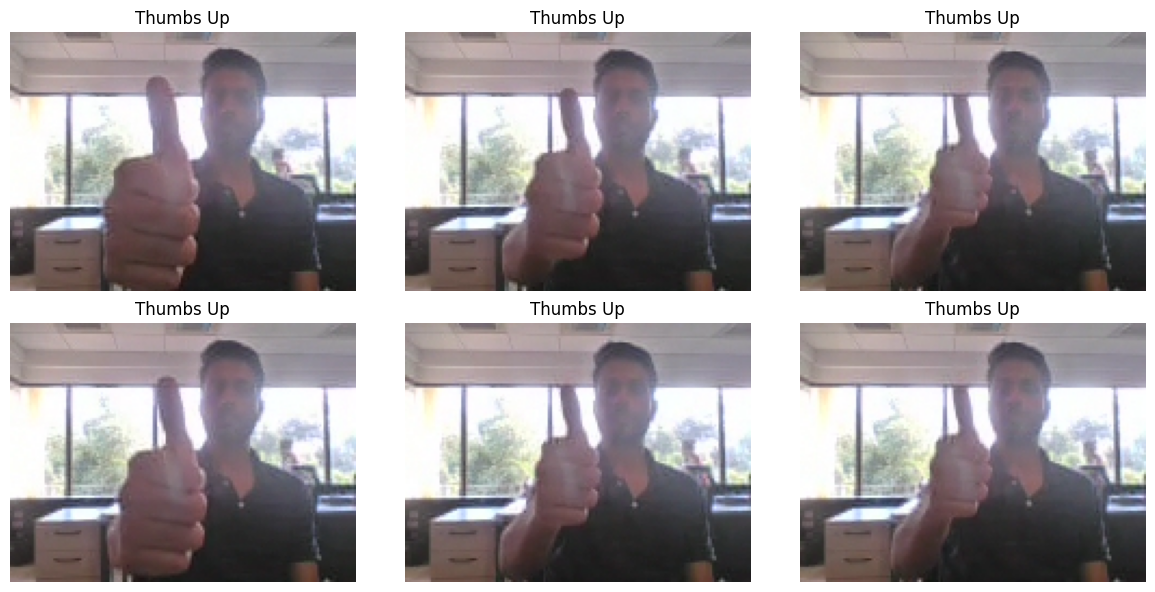

In [26]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Select one thumbs-up folder
sample_folder = os.path.join(
    train_path,
    thumbs_up_folders[0]
)

# Find image files
image_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Display up to 6 images
selected_images = random.sample(
    image_files,
    min(6, len(image_files))
)

plt.figure(figsize=(12, 6))

for i, filename in enumerate(selected_images):
    image_path = os.path.join(sample_folder, filename)
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title("Thumbs Up")
    plt.axis("off")

plt.tight_layout()
plt.show()

Number of thumbs-down folders: 137


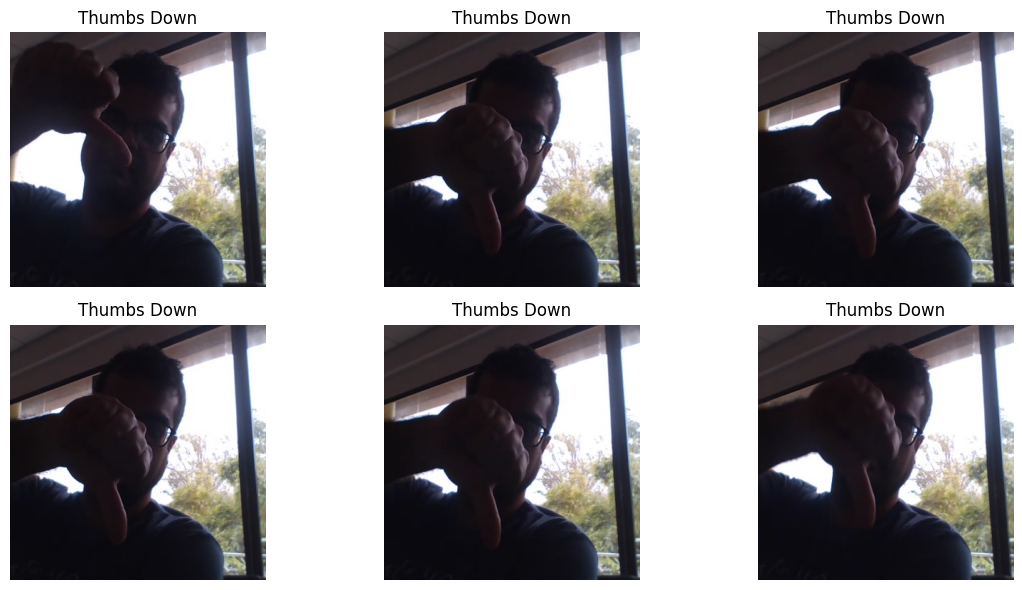

In [27]:
# Find thumbs-down folders
thumbs_down_folders = [
    folder for folder in os.listdir(train_path)
    if "Thumbs_Down_new" in folder
    or "Thumbs Down_new" in folder
]

print("Number of thumbs-down folders:", len(thumbs_down_folders))

# Select one folder
sample_folder = os.path.join(train_path, thumbs_down_folders[0])

# Find images
image_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Display up to 6 images
selected_images = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(12, 6))

for i, filename in enumerate(selected_images):
    image_path = os.path.join(sample_folder, filename)
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title("Thumbs Down")
    plt.axis("off")

plt.tight_layout()
plt.show()

Number of Stop gesture folders: 130


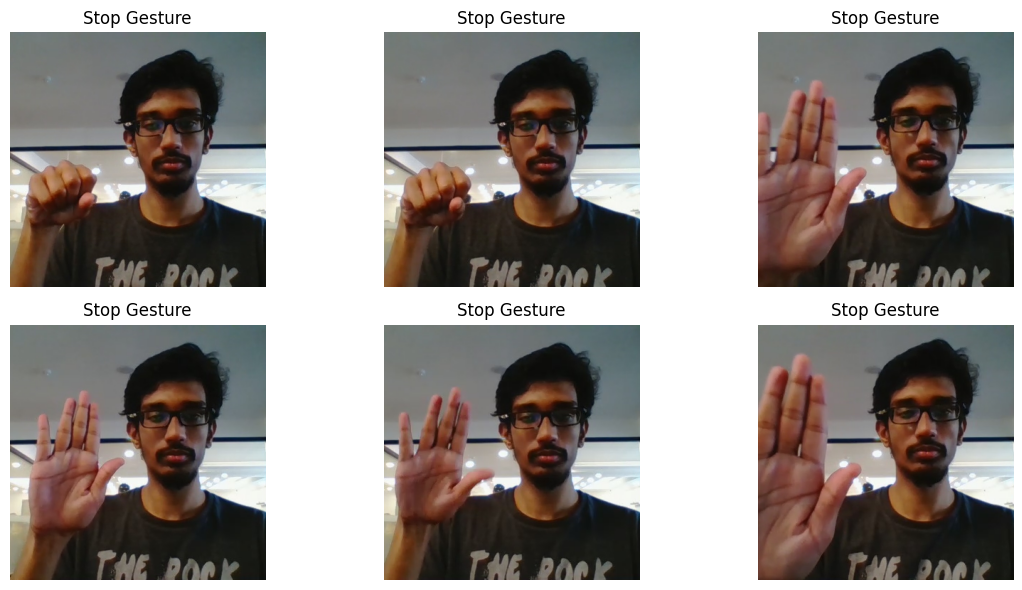

In [28]:
# Find folders containing Stop gestures
stop_folders = [
    folder for folder in os.listdir(train_path)
    if "Stop" in folder
]

print("Number of Stop gesture folders:", len(stop_folders))

# Select one folder
sample_folder = os.path.join(train_path, stop_folders[0])

# Find image files
image_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Display up to 6 images
selected_images = random.sample(
    image_files, min(6, len(image_files))
)

plt.figure(figsize=(12, 6))

for i, filename in enumerate(selected_images):
    image_path = os.path.join(sample_folder, filename)
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title("Stop Gesture")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
import os
import shutil
import random
from PIL import Image

# Folder containing our own webcam images
webcam_dataset_path = "/content/gesture_dataset"

# Folder for the prepared dataset
prepared_dataset_path = "/content/prepared_gesture_dataset"

# Create output folders
classes = ["thumbs_up", "thumbs_down", "neutral"]

for class_name in classes:
    os.makedirs(
        os.path.join(prepared_dataset_path, class_name),
        exist_ok=True
    )

print("Prepared dataset folders created!")

Prepared dataset folders created!


In [30]:
for class_name in classes:
    source_folder = os.path.join(
        webcam_dataset_path, class_name
    )

    destination_folder = os.path.join(
        prepared_dataset_path, class_name
    )

    for filename in os.listdir(source_folder):
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            source = os.path.join(source_folder, filename)
            destination = os.path.join(
                destination_folder, filename
            )

            shutil.copy2(source, destination)

print("Webcam images copied successfully!")

Webcam images copied successfully!


In [31]:
for class_name in classes:
    folder = os.path.join(
        prepared_dataset_path, class_name
    )

    images = [
        name for name in os.listdir(folder)
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    print(f"{class_name}: {len(images)} images")

thumbs_up: 10 images
thumbs_down: 10 images
neutral: 10 images


In [32]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = "/content/prepared_gesture_dataset"

classes = ["thumbs_up", "thumbs_down", "neutral"]

image_size = (64, 64)

X = []
y = []

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder_path, filename)

            # Open the image and convert it to grayscale
            image = Image.open(image_path).convert("L")

            # Resize every image to the same dimensions
            image = image.resize(image_size)

            # Convert the image into a numerical array
            image_array = np.array(image)

            # Flatten the 64 x 64 image into 4096 features
            image_features = image_array.flatten()

            X.append(image_features)
            y.append(class_name)

X = np.array(X)
y = np.array(y)

print("Dataset loaded successfully!")
print("Total images:", len(X))
print("Features per image:", X.shape[1])
print("Labels:", np.unique(y))
print("Dataset shape:", X.shape)

Dataset loaded successfully!
Total images: 30
Features per image: 4096
Labels: ['neutral' 'thumbs_down' 'thumbs_up']
Dataset shape: (30, 4096)


In [33]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("\nTraining class distribution:")
for class_name in classes:
    print(f"{class_name}: {np.sum(y_train == class_name)}")

print("\nTesting class distribution:")
for class_name in classes:
    print(f"{class_name}: {np.sum(y_test == class_name)}")

Data splitting completed!
Training images: 24
Testing images: 6

Training class distribution:
thumbs_up: 8
thumbs_down: 8
neutral: 8

Testing class distribution:
thumbs_up: 2
thumbs_down: 2
neutral: 2


In [34]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the SVM model
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

# Train the model using training data
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [35]:
# Predict the classes of unseen test images
y_pred = svm_model.predict(X_test)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["thumbs_up", "thumbs_down", "neutral"]
))

Test Accuracy: 66.67%

Classification Report:
              precision    recall  f1-score   support

     neutral       0.00      0.00      0.00         2
 thumbs_down       0.50      1.00      0.67         2
   thumbs_up       1.00      1.00      1.00         2

    accuracy                           0.67         6
   macro avg       0.50      0.67      0.56         6
weighted avg       0.50      0.67      0.56         6


Confusion Matrix:
[[2 0 0]
 [0 2 0]
 [0 2 0]]


In [36]:
import os
import pandas as pd

repo_path = "/content/Gesture-Recognition-Dataset"
train_path = os.path.join(repo_path, "train")

train_csv = os.path.join(repo_path, "train.csv")

train_df = pd.read_csv(train_csv, sep=";")

print("Dataset loaded successfully!")
print("Number of training sequences:", len(train_df))

print("\nAvailable gesture labels:")
print(train_df.iloc[:, 1].value_counts())

print("\nExample sequence folders:")
print(os.listdir(train_path)[:5])

Dataset loaded successfully!
Number of training sequences: 662

Available gesture labels:
Left_Swipe_new
Right_Swipe_new                  103
Thumbs_Down_new                  100
Left_Swipe_new                    95
Stop_new                          93
Thumbs_Up_new                     87
Left Swipe_new_Left Swipe_new     40
Stop Gesture_new                  37
Thumbs Down_new                   37
Thumbs Up_new                     36
Right Swipe_new                   34
Name: count, dtype: int64

Example sequence folders:
['WIN_20180907_16_52_18_Pro_Stop Gesture_new', 'WIN_20180907_15_56_26_Pro_Thumbs Up_new', 'WIN_20180926_17_11_41_Pro_Left_Swipe_new', 'WIN_20180926_17_42_43_Pro_Right_Swipe_new', 'WIN_20180926_17_33_09_Pro_Thumbs_Up_new']


In [37]:
# Identify public dataset sequences for each target class

thumbs_up_folders = [
    folder for folder in os.listdir(train_path)
    if "Thumbs_Up_new" in folder or "Thumbs Up_new" in folder
]

thumbs_down_folders = [
    folder for folder in os.listdir(train_path)
    if "Thumbs_Down_new" in folder or "Thumbs Down_new" in folder
]

stop_folders = [
    folder for folder in os.listdir(train_path)
    if "Stop_new" in folder or "Stop Gesture_new" in folder
]

print("Thumbs-up sequences:", len(thumbs_up_folders))
print("Thumbs-down sequences:", len(thumbs_down_folders))
print("Stop sequences to inspect:", len(stop_folders))

Thumbs-up sequences: 123
Thumbs-down sequences: 137
Stop sequences to inspect: 130


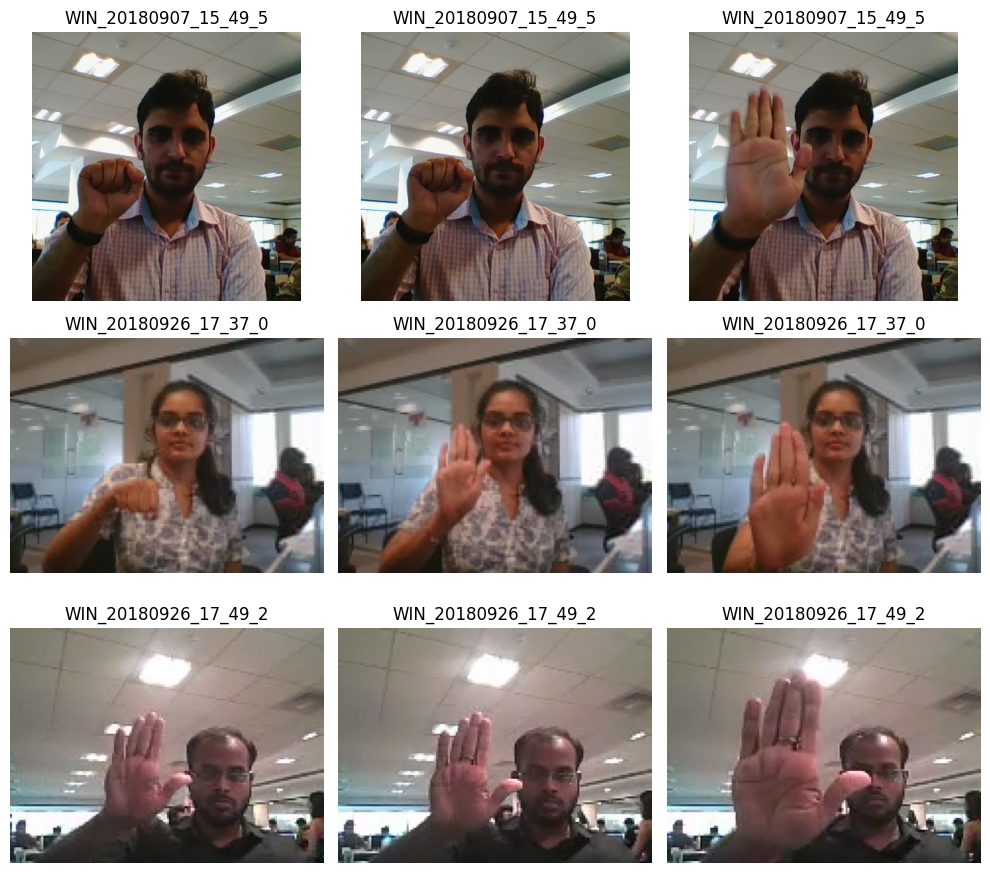

In [38]:
import random
from PIL import Image
import matplotlib.pyplot as plt

random.seed(42)

sample_folders = random.sample(
    stop_folders,
    min(3, len(stop_folders))
)

fig, axes = plt.subplots(
    len(sample_folders), 3,
    figsize=(10, 3 * len(sample_folders))
)

if len(sample_folders) == 1:
    axes = np.array([axes])

for row, folder in enumerate(sample_folders):
    folder_path = os.path.join(train_path, folder)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if not image_files:
        continue

    selected_images = np.linspace(
        0, len(image_files) - 1,
        min(3, len(image_files)),
        dtype=int
    )

    for col, image_index in enumerate(selected_images):
        image = Image.open(
            os.path.join(folder_path, image_files[image_index])
        )

        axes[row, col].imshow(image)
        axes[row, col].set_title(folder[:20])
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [39]:
import os
import shutil

public_dataset_path = "/content/Gesture-Recognition-Dataset/train"
combined_dataset_path = "/content/combined_gesture_dataset"

classes = ["thumbs_up", "thumbs_down", "neutral"]

for class_name in classes:
    os.makedirs(
        os.path.join(combined_dataset_path, class_name),
        exist_ok=True
    )

# Copy our original webcam images
webcam_dataset_path = "/content/prepared_gesture_dataset"

for class_name in classes:
    source_folder = os.path.join(webcam_dataset_path, class_name)
    destination_folder = os.path.join(
        combined_dataset_path, class_name
    )

    for filename in os.listdir(source_folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            shutil.copy2(
                os.path.join(source_folder, filename),
                os.path.join(destination_folder, filename)
            )

print("Webcam images copied into the combined dataset!")

Webcam images copied into the combined dataset!


In [40]:
import os

for class_name in classes:
    folder = os.path.join(combined_dataset_path, class_name)

    image_count = sum(
        1 for filename in os.listdir(folder)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    print(f"{class_name}: {image_count} images")

thumbs_up: 10 images
thumbs_down: 10 images
neutral: 10 images


In [41]:
import os
import shutil
import random

random.seed(42)

public_dataset_path = "/content/Gesture-Recognition-Dataset/train"

# Map public dataset labels to our class names
gesture_groups = {
    "thumbs_up": ["Thumbs_Up_new", "Thumbs Up_new"],
    "thumbs_down": ["Thumbs_Down_new", "Thumbs Down_new"]
}

for target_class, label_patterns in gesture_groups.items():

    destination_folder = os.path.join(
        combined_dataset_path, target_class
    )

    os.makedirs(destination_folder, exist_ok=True)

    sequence_folders = [
        folder for folder in os.listdir(public_dataset_path)
        if any(pattern in folder for pattern in label_patterns)
    ]

    print(f"\nProcessing {target_class}: {len(sequence_folders)} sequences")

    added_images = 0

    for sequence in sequence_folders:
        sequence_path = os.path.join(public_dataset_path, sequence)

        image_files = sorted([
            filename for filename in os.listdir(sequence_path)
            if filename.lower().endswith((".png", ".jpg", ".jpeg"))
        ])

        if not image_files:
            continue

        # Select up to 5 frames spread across the sequence
        selected_indices = list(
            range(0, len(image_files), max(1, len(image_files) // 5))
        )[:5]

        for index in selected_indices:
            filename = image_files[index]

            source_path = os.path.join(sequence_path, filename)

            # Include the sequence name to avoid filename collisions
            destination_name = f"{sequence}__{filename}"
            destination_path = os.path.join(
                destination_folder, destination_name
            )

            shutil.copy2(source_path, destination_path)
            added_images += 1

    print(f"Public images copied: {added_images}")

print("\nPublic thumbs-up and thumbs-down images added!")


Processing thumbs_up: 123 sequences
Public images copied: 615

Processing thumbs_down: 137 sequences
Public images copied: 685

Public thumbs-up and thumbs-down images added!


In [42]:
for class_name in classes:
    folder = os.path.join(combined_dataset_path, class_name)

    image_count = sum(
        1 for filename in os.listdir(folder)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    print(f"{class_name}: {image_count} images")

thumbs_up: 625 images
thumbs_down: 695 images
neutral: 10 images


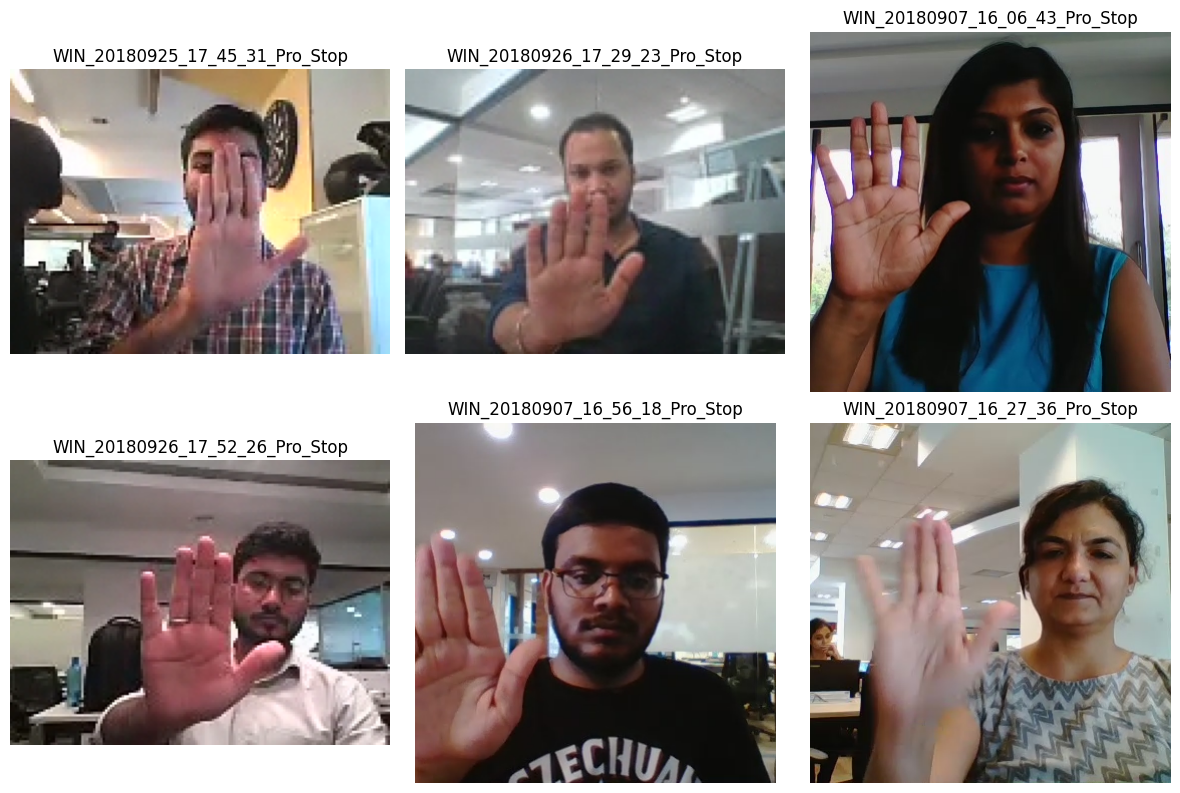

In [43]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(10)

public_dataset_path = "/content/Gesture-Recognition-Dataset/train"

stop_folders = [
    folder for folder in os.listdir(public_dataset_path)
    if "Stop_new" in folder or "Stop Gesture_new" in folder
]

sample_folders = random.sample(
    stop_folders,
    min(6, len(stop_folders))
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i, folder in enumerate(sample_folders):
    folder_path = os.path.join(public_dataset_path, folder)

    image_files = sorted([
        filename for filename in os.listdir(folder_path)
        if filename.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if image_files:
        # Inspect a frame near the middle of the sequence
        middle_index = len(image_files) // 2
        image_path = os.path.join(
            folder_path, image_files[middle_index]
        )

        image = Image.open(image_path)

        axes[i].imshow(image)
        axes[i].set_title(folder[:30])
        axes[i].axis("off")

for i in range(len(sample_folders), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [44]:
import os
import shutil

public_dataset_path = "/content/Gesture-Recognition-Dataset/train"

neutral_folder = os.path.join(
    combined_dataset_path, "neutral"
)
os.makedirs(neutral_folder, exist_ok=True)

# Select only Stop sequences that have been inspected.
# These are the six sequences displayed in your previous cell.
verified_stop_folders = sample_folders

added_images = 0

for sequence in verified_stop_folders:
    sequence_path = os.path.join(public_dataset_path, sequence)

    image_files = sorted([
        filename for filename in os.listdir(sequence_path)
        if filename.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if not image_files:
        continue

    # Select up to five frames spread across the sequence
    indices = np.linspace(
        0, len(image_files) - 1,
        min(5, len(image_files)),
        dtype=int
    )

    for index in indices:
        filename = image_files[index]

        source_path = os.path.join(sequence_path, filename)
        destination_name = f"{sequence}__{filename}"
        destination_path = os.path.join(
            neutral_folder, destination_name
        )

        if not os.path.exists(destination_path):
            shutil.copy2(source_path, destination_path)
            added_images += 1

print("Neutral images added:", added_images)

Neutral images added: 30


In [45]:
for class_name in classes:
    folder = os.path.join(combined_dataset_path, class_name)

    image_count = sum(
        1 for filename in os.listdir(folder)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    print(f"{class_name}: {image_count} images")

thumbs_up: 625 images
thumbs_down: 695 images
neutral: 40 images


In [46]:
import os
import random
import shutil

random.seed(42)

balanced_dataset_path = "/content/balanced_gesture_dataset"

for class_name in classes:
    source_folder = os.path.join(combined_dataset_path, class_name)
    destination_folder = os.path.join(balanced_dataset_path, class_name)

    os.makedirs(destination_folder, exist_ok=True)

    image_files = sorted([
        filename for filename in os.listdir(source_folder)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    selected_images = random.sample(
        image_files,
        min(40, len(image_files))
    )

    for filename in selected_images:
        shutil.copy2(
            os.path.join(source_folder, filename),
            os.path.join(destination_folder, filename)
        )

    print(f"{class_name}: {len(selected_images)} images selected")

print("\nBalanced dataset prepared!")

thumbs_up: 40 images selected
thumbs_down: 40 images selected
neutral: 40 images selected

Balanced dataset prepared!


In [47]:
for class_name in classes:
    folder = os.path.join(balanced_dataset_path, class_name)

    image_count = len([
        filename for filename in os.listdir(folder)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{class_name}: {image_count} images")

thumbs_up: 40 images
thumbs_down: 40 images
neutral: 40 images


In [48]:
import os
import numpy as np
from PIL import Image

balanced_dataset_path = "/content/balanced_gesture_dataset"

classes = ["thumbs_up", "thumbs_down", "neutral"]
image_size = (64, 64)

X = []
y = []

for class_name in classes:
    folder_path = os.path.join(balanced_dataset_path, class_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder_path, filename)

            image = Image.open(image_path).convert("L")
            image = image.resize(image_size)

            image_features = np.array(image).flatten()

            X.append(image_features)
            y.append(class_name)

X = np.array(X)
y = np.array(y)

print("Dataset loaded successfully!")
print("Total images:", len(X))
print("Features per image:", X.shape[1])
print("Dataset shape:", X.shape)

for class_name in classes:
    print(f"{class_name}: {np.sum(y == class_name)} images")

Dataset loaded successfully!
Total images: 120
Features per image: 4096
Dataset shape: (120, 4096)
thumbs_up: 40 images
thumbs_down: 40 images
neutral: 40 images


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 96
Testing images: 24


In [50]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create the SVM pipeline
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

# Train the model
svm_model.fit(X_train, y_train)

print("Improved SVM model trained successfully!")

Improved SVM model trained successfully!


Test Accuracy: 79.17%

Classification Report:
              precision    recall  f1-score   support

   thumbs_up       0.75      0.75      0.75         8
 thumbs_down       0.67      0.75      0.71         8
     neutral       1.00      0.88      0.93         8

    accuracy                           0.79        24
   macro avg       0.81      0.79      0.80        24
weighted avg       0.81      0.79      0.80        24



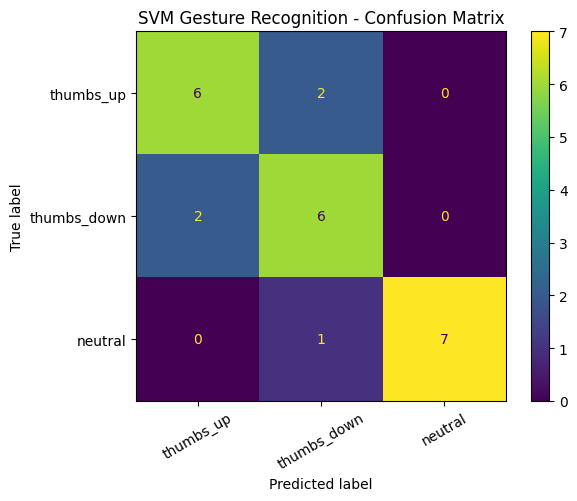

In [51]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict the test images
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        zero_division=0
    )
)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=classes)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot()
plt.title("SVM Gesture Recognition - Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

<IPython.core.display.Javascript object>

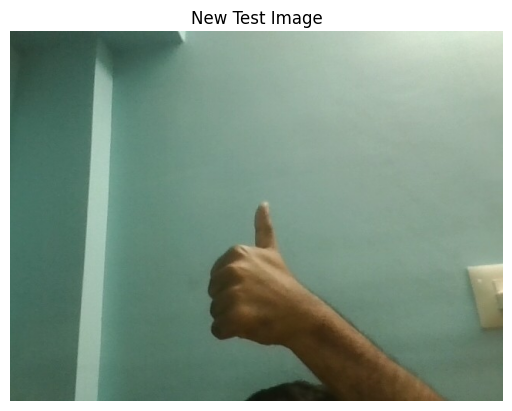

In [52]:
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

# Capture a new photo using your webcam
test_image = capture_image()

plt.imshow(test_image)
plt.title("New Test Image")
plt.axis("off")
plt.show()

In [53]:
import numpy as np

# Convert the image into the format used during training
processed_image = test_image.convert("L")
processed_image = processed_image.resize((64, 64))

image_features = np.array(processed_image).flatten()
image_features = image_features.reshape(1, -1)

# Predict the gesture
prediction = svm_model.predict(image_features)[0]

print("Predicted gesture:", prediction)

Predicted gesture: neutral


In [54]:
# Normalize the pixel values
X_train_normalized = X_train / 255.0
X_test_normalized = X_test / 255.0

print("Training data shape:", X_train_normalized.shape)
print("Testing data shape:", X_test_normalized.shape)
print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Training data shape: (96, 4096)
Testing data shape: (24, 4096)
Minimum pixel value: 0.01568627450980392
Maximum pixel value: 1.0


In [55]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

svm_model.fit(X_train_normalized, y_train)

print("Normalized SVM model trained successfully!")

Normalized SVM model trained successfully!


In [56]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = svm_model.predict(X_test_normalized)

print(
    f"Normalized SVM Test Accuracy: "
    f"{accuracy_score(y_test, y_pred) * 100:.2f}%"
)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        zero_division=0
    )
)

Normalized SVM Test Accuracy: 79.17%
              precision    recall  f1-score   support

   thumbs_up       0.75      0.75      0.75         8
 thumbs_down       0.67      0.75      0.71         8
     neutral       1.00      0.88      0.93         8

    accuracy                           0.79        24
   macro avg       0.81      0.79      0.80        24
weighted avg       0.81      0.79      0.80        24



In [57]:
# Use the same captured image for a fair comparison
processed_image = test_image.convert("L")
processed_image = processed_image.resize((64, 64))

image_features = np.array(processed_image).flatten().reshape(1, -1)
image_features = image_features / 255.0

prediction = svm_model.predict(image_features)[0]

print("Predicted gesture:", prediction)

Predicted gesture: neutral


In [58]:
from skimage.feature import hog
import numpy as np

def extract_hog_features(images):
    features = []

    for image_array in images:
        image_array = image_array.reshape(64, 64)

        hog_features = hog(
            image_array,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(hog_features)

    return np.array(features)


X_train_hog = extract_hog_features(X_train_normalized)
X_test_hog = extract_hog_features(X_test_normalized)

print("HOG training shape:", X_train_hog.shape)
print("HOG testing shape:", X_test_hog.shape)
print("HOG feature extraction completed!")

HOG training shape: (96, 1764)
HOG testing shape: (24, 1764)
HOG feature extraction completed!


In [59]:
!pip install scikit-image

In [60]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

hog_svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

hog_svm_model.fit(X_train_hog, y_train)

print("HOG + SVM model trained successfully!")

HOG + SVM model trained successfully!


In [61]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_hog = hog_svm_model.predict(X_test_hog)

hog_accuracy = accuracy_score(y_test, y_pred_hog)

print(f"HOG + SVM Test Accuracy: {hog_accuracy * 100:.2f}%")

print(
    classification_report(
        y_test,
        y_pred_hog,
        labels=classes,
        zero_division=0
    )
)

HOG + SVM Test Accuracy: 83.33%
              precision    recall  f1-score   support

   thumbs_up       0.78      0.88      0.82         8
 thumbs_down       0.75      0.75      0.75         8
     neutral       1.00      0.88      0.93         8

    accuracy                           0.83        24
   macro avg       0.84      0.83      0.84        24
weighted avg       0.84      0.83      0.84        24



In [62]:
from skimage.feature import hog
import numpy as np

processed_image = test_image.convert("L")
processed_image = processed_image.resize((64, 64))

image_array = np.array(processed_image).astype(np.float32) / 255.0

test_hog = hog(
    image_array,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys"
).reshape(1, -1)

prediction = hog_svm_model.predict(test_hog)[0]

print("Predicted gesture:", prediction)

Predicted gesture: thumbs_up


In [63]:
import joblib

model_path = "/content/gesture_recognition_model.pkl"

joblib.dump(hog_svm_model, model_path)

print("HOG + SVM model saved successfully!")
print("File:", model_path)

HOG + SVM model saved successfully!
File: /content/gesture_recognition_model.pkl


In [64]:
from google.colab import files

files.download("/content/gesture_recognition_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>